DAY 12: GRID CONVERGENCE STUDY
Rayleigh number: 2500.0
Grid sizes: [21, 31, 41]

Running grid 21 x 21
Steps: 1741
Final time: 0.025
Maximum velocity: 620.0779791212287
Bottom Nu: 6.853009811472079
Top Nu: 10.997645461013136

Running grid 31 x 31
Steps: 2759
Final time: 0.025
Maximum velocity: 655.8371524716465
Bottom Nu: 8.077109742379667
Top Nu: 11.995552416180347

Running grid 41 x 41
Steps: 3340
Final time: 0.025
Maximum velocity: 488.31934604630914
Bottom Nu: 9.746131680907636
Top Nu: 12.4540519764337

Summary saved: day12_grid_convergence\day12_grid_summary.csv


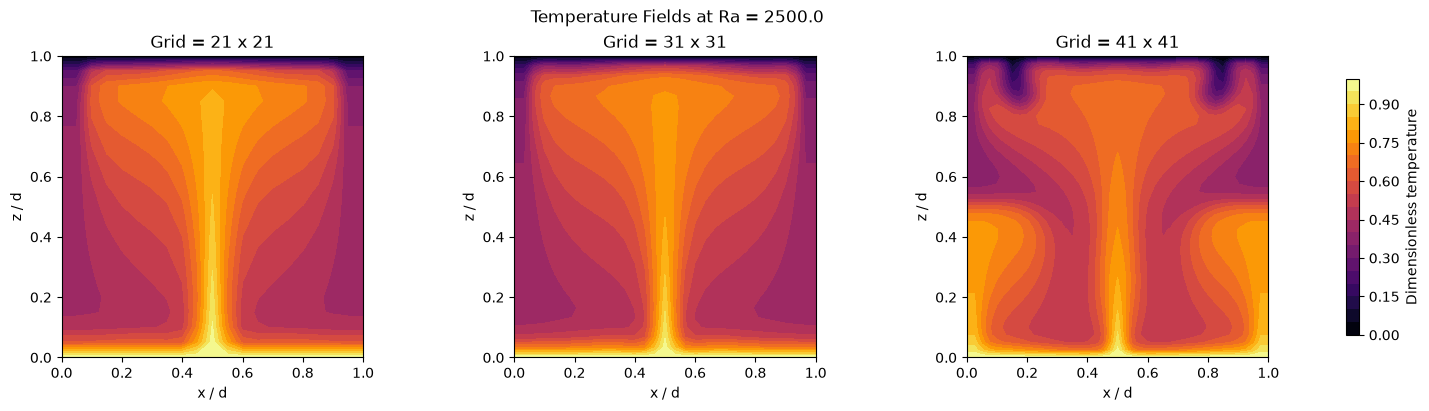

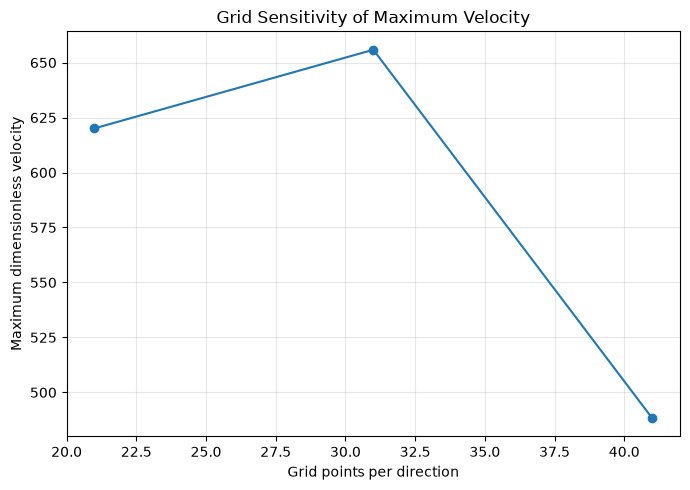

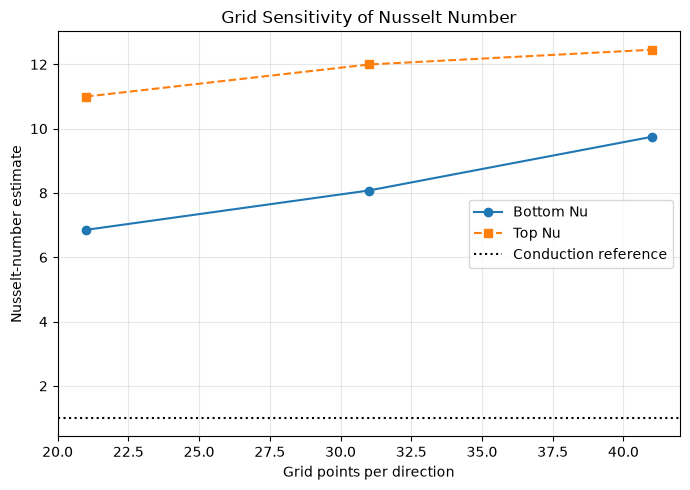


DAY 12 COMPLETED
Results folder: C:\Users\athil\OneDrive\Desktop\day12_grid_convergence
Generated files:
1. day12_grid_summary.csv
2. day12_temperature_comparison.png
3. day12_velocity_convergence.png
4. day12_nusselt_convergence.png

Compare the values as grid spacing decreases.
This is a preliminary grid-sensitivity test,
not proof of full numerical convergence.


In [1]:
"""
DAY 12: GRID CONVERGENCE STUDY
2-D Numerical Modelling of Mantle Convection

Objectives:
1. Compare different grid resolutions.
2. Compare maximum velocity.
3. Compare Nusselt-number estimates.
4. Compare final temperature fields.
5. Save a CSV summary and plots.

Required libraries:
pip install numpy scipy matplotlib
"""

from pathlib import Path
import csv
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import lil_matrix
from scipy.sparse.linalg import factorized


# ============================================================
# 1. SETTINGS
# ============================================================

RA = 2500.0
GRID_SIZES = [21, 31, 41]
END_TIME = 0.025
PERTURBATION = 0.015

DT_SAFETY = 0.20
MAX_STEPS = 200000

OUTPUT_DIR = Path("day12_grid_convergence")
OUTPUT_DIR.mkdir(exist_ok=True)

print("DAY 12: GRID CONVERGENCE STUDY")
print("Rayleigh number:", RA)
print("Grid sizes:", GRID_SIZES)


# ============================================================
# 2. GRID
# ============================================================

def make_grid(n):

    x = np.linspace(0, 1, n)
    z = np.linspace(0, 1, n)

    X, Z = np.meshgrid(x, z)

    dx = x[1] - x[0]
    dz = z[1] - z[0]

    return x, z, X, Z, dx, dz


# ============================================================
# 3. NUMERICAL DERIVATIVES
# ============================================================

def laplacian(T, dx, dz):

    result = np.zeros_like(T)

    result[1:-1, 1:-1] = (
        (T[1:-1, 2:] - 2*T[1:-1, 1:-1]
         + T[1:-1, :-2]) / dx**2
        +
        (T[2:, 1:-1] - 2*T[1:-1, 1:-1]
         + T[:-2, 1:-1]) / dz**2
    )

    return result


def derivative_x(field, dx):
    return np.gradient(field, dx, axis=1, edge_order=2)


def derivative_z(field, dz):
    return np.gradient(field, dz, axis=0, edge_order=2)


# ============================================================
# 4. STREAMFUNCTION SOLVER
# ============================================================

def create_streamfunction_solver(n, dx, dz):

    m = n - 2
    L = lil_matrix((m*m, m*m), dtype=float)

    def index(i, j):
        return (i - 1)*m + (j - 1)

    for i in range(1, n-1):
        for j in range(1, n-1):

            k = index(i, j)

            L[k, k] = -2/dx**2 - 2/dz**2

            if j > 1:
                L[k, index(i, j-1)] = 1/dx**2

            if j < n-2:
                L[k, index(i, j+1)] = 1/dx**2

            if i > 1:
                L[k, index(i-1, j)] = 1/dz**2

            if i < n-2:
                L[k, index(i+1, j)] = 1/dz**2

    solve = factorized(L.tocsc())

    def calculate_psi(rhs):

        psi = np.zeros_like(rhs)

        psi[1:-1, 1:-1] = solve(
            rhs[1:-1, 1:-1].ravel()
        ).reshape(m, m)

        return psi

    return calculate_psi


# ============================================================
# 5. TEMPERATURE BOUNDARIES
# ============================================================

def apply_boundaries(T):

    T[0, :] = 1.0
    T[-1, :] = 0.0

    # Approximate insulating sidewalls.
    T[:, 0] = T[:, 1]
    T[:, -1] = T[:, -2]

    T[0, :] = 1.0
    T[-1, :] = 0.0

    return T


# ============================================================
# 6. NUSSELT NUMBER
# ============================================================

def calculate_nusselt(T, dz):

    bottom_gradient = (
        T[1, 1:-1] - T[0, 1:-1]
    ) / dz

    top_gradient = (
        T[-1, 1:-1] - T[-2, 1:-1]
    ) / dz

    nu_bottom = -float(np.mean(bottom_gradient))
    nu_top = -float(np.mean(top_gradient))

    mismatch = (
        100 * abs(nu_bottom - nu_top)
        / max(abs(nu_bottom), abs(nu_top), 1e-12)
    )

    return nu_bottom, nu_top, mismatch


# ============================================================
# 7. RUN ONE GRID
# ============================================================

def run_simulation(n):

    x, z, X, Z, dx, dz = make_grid(n)

    T = (
        1 - Z
        + PERTURBATION
        * np.sin(np.pi*X)
        * np.sin(np.pi*Z)
    )

    T = apply_boundaries(T)

    solve_psi = create_streamfunction_solver(n, dx, dz)

    time = 0.0
    steps = 0

    print(f"\nRunning grid {n} x {n}")

    while time < END_TIME and steps < MAX_STEPS:

        # Calculate velocity.
        psi = solve_psi(
            -RA*derivative_x(T, dx)
        )

        u = derivative_z(psi, dz)
        w = -derivative_x(psi, dx)

        speed = np.sqrt(u**2 + w**2)

        max_speed = float(
            np.max(speed[1:-1, 1:-1])
        )

        # Estimate a stable time step.
        dt_diffusion = DT_SAFETY / (
            2*(1/dx**2 + 1/dz**2)
        )

        if max_speed > 1e-12:
            dt_advection = 0.35 / (
                max_speed*(1/dx + 1/dz)
            )
        else:
            dt_advection = dt_diffusion

        dt = min(
            dt_diffusion,
            dt_advection,
            END_TIME - time
        )

        if not np.isfinite(dt) or dt <= 0:
            raise RuntimeError(
                f"Invalid time step for grid {n}"
            )

        # Upwind derivatives for advection.
        dTdx_up = np.zeros_like(T)
        dTdz_up = np.zeros_like(T)

        dTdx_up[:, 1:-1] = np.where(
            u[:, 1:-1] >= 0,
            (T[:, 1:-1] - T[:, :-2])/dx,
            (T[:, 2:] - T[:, 1:-1])/dx
        )

        dTdz_up[1:-1, :] = np.where(
            w[1:-1, :] >= 0,
            (T[1:-1, :] - T[:-2, :])/dz,
            (T[2:, :] - T[1:-1, :])/dz
        )

        lap_T = laplacian(T, dx, dz)

        T_new = T.copy()

        T_new[1:-1, 1:-1] = (
            T[1:-1, 1:-1]
            + dt*(
                -u[1:-1, 1:-1]
                * dTdx_up[1:-1, 1:-1]
                -w[1:-1, 1:-1]
                * dTdz_up[1:-1, 1:-1]
                +lap_T[1:-1, 1:-1]
            )
        )

        T = apply_boundaries(T_new)

        time += dt
        steps += 1

    if time < END_TIME:
        print("WARNING: Maximum step count reached.")

    # Calculate final velocity.
    psi = solve_psi(
        -RA*derivative_x(T, dx)
    )

    u = derivative_z(psi, dz)
    w = -derivative_x(psi, dx)

    speed = np.sqrt(u**2 + w**2)

    nu_bottom, nu_top, mismatch = calculate_nusselt(T, dz)

    result = {
        "n": n,
        "x": x,
        "z": z,
        "X": X,
        "Z": Z,
        "T": T,
        "u": u,
        "w": w,
        "speed": speed,
        "final_time": time,
        "steps": steps,
        "max_speed": float(np.max(speed[1:-1, 1:-1])),
        "Nu_bottom": nu_bottom,
        "Nu_top": nu_top,
        "Nu_mismatch": mismatch,
        "temperature_min": float(np.min(T)),
        "temperature_max": float(np.max(T))
    }

    print("Steps:", steps)
    print("Final time:", time)
    print("Maximum velocity:", result["max_speed"])
    print("Bottom Nu:", nu_bottom)
    print("Top Nu:", nu_top)

    return result


# ============================================================
# 8. RUN ALL GRID SIZES
# ============================================================

results = []

for n in GRID_SIZES:

    result = run_simulation(n)
    results.append(result)


# ============================================================
# 9. SAVE CSV SUMMARY
# ============================================================

summary = []

for r in results:

    summary.append({
        "Rayleigh_number": RA,
        "grid_size": r["n"],
        "grid_spacing": 1/(r["n"]-1),
        "final_time": r["final_time"],
        "steps": r["steps"],
        "maximum_velocity": r["max_speed"],
        "Nu_bottom": r["Nu_bottom"],
        "Nu_top": r["Nu_top"],
        "Nu_mismatch_percent": r["Nu_mismatch"],
        "temperature_min": r["temperature_min"],
        "temperature_max": r["temperature_max"]
    })

csv_file = OUTPUT_DIR / "day12_grid_summary.csv"

with open(csv_file, "w", newline="", encoding="utf-8") as f:

    writer = csv.DictWriter(
        f, fieldnames=list(summary[0].keys())
    )

    writer.writeheader()
    writer.writerows(summary)

print("\nSummary saved:", csv_file)


# ============================================================
# 10. PLOT TEMPERATURE FIELDS
# ============================================================

fig, axes = plt.subplots(
    1, len(results),
    figsize=(5*len(results), 4),
    squeeze=False,
    constrained_layout=True
)

last_contour = None

for ax, r in zip(axes[0], results):

    last_contour = ax.contourf(
        r["X"], r["Z"], r["T"],
        levels=21, cmap="inferno"
    )

    ax.set_title(f"Grid = {r['n']} x {r['n']}")
    ax.set_xlabel("x / d")
    ax.set_ylabel("z / d")
    ax.set_aspect("equal")

fig.colorbar(
    last_contour,
    ax=axes.ravel().tolist(),
    label="Dimensionless temperature",
    shrink=0.85
)

fig.suptitle(f"Temperature Fields at Ra = {RA}")

fig.savefig(
    OUTPUT_DIR / "day12_temperature_comparison.png",
    dpi=180
)

plt.show()


# ============================================================
# 11. MAXIMUM VELOCITY VS GRID SIZE
# ============================================================

grid_sizes = [r["n"] for r in results]
velocities = [r["max_speed"] for r in results]

plt.figure(figsize=(7, 5))

plt.plot(grid_sizes, velocities, "o-")

plt.xlabel("Grid points per direction")
plt.ylabel("Maximum dimensionless velocity")
plt.title("Grid Sensitivity of Maximum Velocity")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "day12_velocity_convergence.png",
    dpi=180
)

plt.show()


# ============================================================
# 12. NUSSELT NUMBER VS GRID SIZE
# ============================================================

nu_bottom = [r["Nu_bottom"] for r in results]
nu_top = [r["Nu_top"] for r in results]

plt.figure(figsize=(7, 5))

plt.plot(grid_sizes, nu_bottom, "o-", label="Bottom Nu")
plt.plot(grid_sizes, nu_top, "s--", label="Top Nu")

plt.axhline(
    1, color="black", linestyle=":",
    label="Conduction reference"
)

plt.xlabel("Grid points per direction")
plt.ylabel("Nusselt-number estimate")
plt.title("Grid Sensitivity of Nusselt Number")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "day12_nusselt_convergence.png",
    dpi=180
)

plt.show()


# ============================================================
# 13. FINISH
# ============================================================

print("\n" + "="*55)
print("DAY 12 COMPLETED")
print("="*55)

print("Results folder:", OUTPUT_DIR.resolve())

print("Generated files:")
print("1. day12_grid_summary.csv")
print("2. day12_temperature_comparison.png")
print("3. day12_velocity_convergence.png")
print("4. day12_nusselt_convergence.png")

print("\nCompare the values as grid spacing decreases.")
print("This is a preliminary grid-sensitivity test,")
print("not proof of full numerical convergence.")